# Data Exploration - Possible Asteroid Impacts with Earth

The skeleton of this notebook was created by AI, using the 'guided' version of data exploration primer as a template. All the conclusions and substansive value was created by me.

One row summarizes **one asteroid and its possible impact scenarios** in this
dataset. These are model estimates, not a record of observed collisions.

In [99]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams.update({"figure.figsize": (7, 4), "axes.grid": False})

In [100]:
data_path = Path("./impacts.csv")
raw = pd.read_csv(data_path, dtype="string")
print("Loaded:", data_path.resolve())
print("Rows and columns:", raw.shape)
display(raw.head())

Loaded: /home/mati/developer/uj/data-science/2_data_exploration_advanced/impacts.csv
Rows and columns: (683, 11)


,Object Name,Period Start,Period End,Possible Impacts,Cumulative Impact Probability,Asteroid Velocity,Asteroid Magnitude,Asteroid Diameter (km),Cumulative Palermo Scale,Maximum Palermo Scale,Maximum Torino Scale
0,2006 WP1,2017,2017,1,5.2E-09,17.77,28.3,0.007,-8.31,-8.31,0
1,2013 YB,2017,2046,23,7.6E-05,8.98,31.4,0.002,-6.6,-6.96,0
2,2008 US,2017,2062,30,1.6E-05,18.33,31.4,0.002,-6.48,-6.87,0
3,2010 VR139,2017,2076,24,2E-07,4.99,26.7,0.016,-6.83,-6.95,0
4,2015 ME131,2017,2096,85,2.3E-08,19.46,19.2,0.497,-3.85,-4.3,0


### Data preparation
| CSV column → short name | Meaning | Statistical role / cavea |
|---|---|---|
| `Object Name` → `object_name` | Asteroid designation | Identifier |
| `Period Start` → `period_start` | Earliest potential-impact year | Calendar year |
| `Period End` → `period_end` | Latest potential-impact year | Calendar year |
| `Possible Impacts` → `possible_impacts` | Number of potential impact solutions | Count |
| `Cumulative Impact Probability` → `impact_probability` | Combined probability across solutions | Fraction from 0 to 1 |
| `Asteroid Velocity` → `velocity_km_s` | Relative speed, km/s | Sentry's excess velocity excludes Earth's gravitational acceleration |
| `Asteroid Magnitude` → `absolute_magnitude` | Absolute magnitude H | Brightness scale; smaller H means brighter |
| `Asteroid Diameter (km)` → `diameter_km` | Estimated diameter, km | Approximate; often inferred from H and assumed reflectivity |
| `Cumulative Palermo Scale` → `palermo_cumulative` | Combined Palermo rating | Logarithmic risk scale |
| `Maximum Palermo Scale` → `palermo_max` | Highest individual Palermo rating | Logarithmic risk scale |
| `Maximum Torino Scale` → `torino_max` | Highest Torino rating | Ordered category from 0 to 10 |

#### Palermo rating
The scale compares the likelihood of the detected potential impact with the average risk posed by objects of the same size or larger over the years until the date of the potential impact. This average risk from random impacts is known as the background risk. For convenience the scale is logarithmic, so, for examples, a Palermo Scale value of -2 indicates that the detected potential impact event is only 1% as likely as a random background event occurring in the intervening years, a value of zero indicates that the single event is just as threatening as the background hazard, and a value of +2 indicates an event that is 100 times more likely than a background impact by an object at least as large before the date of the potential impact in question.

#### Torino scale
The Torino Scale, adopted by the IAU in 1999, is a tool for categorizing potential Earth impact events. An integer scale ranging from 0 to 10 with associated color coding, it is intended primarily to facilitate public communication by the asteroid impact hazard monitoring community. The scale captures the likelihood and consequences of a potential impact event, but does not consider the time remaining until the potential impact. More extraordinary events are indicated by a higher Torino Scale value.

Definitions: [NASA/JPL Sentry object table](https://cneos.jpl.nasa.gov/sentry/)
and [Sentry API field documentation](https://ssd-api.jpl.nasa.gov/doc/sentry.html).

In [123]:
# Preparing the dataset: renaming columns to a simpler name, making number values have a numeric type instead of a string
column_names = {
    "Object Name": "object_name",
    "Period Start": "period_start",
    "Period End": "period_end",
    "Possible Impacts": "possible_impacts",
    "Cumulative Impact Probability": "impact_probability",
    "Asteroid Velocity": "velocity_km_s",
    "Asteroid Magnitude": "absolute_magnitude",
    "Asteroid Diameter (km)": "diameter_km",
    "Cumulative Palermo Scale": "palermo_cumulative",
    "Maximum Palermo Scale": "palermo_max",
    "Maximum Torino Scale": "torino_max",
}

asteroids = raw.copy()
asteroids.columns = asteroids.columns.str.strip()
if not asteroids.columns.is_unique:
    raise ValueError("Duplicate column names: inspect the CSV header before continuing.")
missing_columns = set(column_names) - set(asteroids.columns)
if missing_columns:
    raise ValueError(f"Unexpected CSV schema; missing columns: {sorted(missing_columns)}")

asteroids = asteroids.rename(columns=column_names)
numeric_columns = [name for name in column_names.values() if name != "object_name"]
conversion_failures = {}
for name in column_names.values():
    text = asteroids[name].str.strip().replace("", pd.NA)
    if name != "object_name":
        converted = pd.to_numeric(text, errors="coerce")
        conversion_failures[name] = int((text.notna() & converted.isna()).sum())

for name in numeric_columns:
    asteroids[name] = pd.to_numeric(asteroids[name], errors="coerce")

In [124]:
print("Non-empty values that could not be parsed (inspect raw if any are nonzero):")
pd.Series(conversion_failures, name="conversion_failures")

Non-empty values that could not be parsed (inspect raw if any are nonzero):


period_start          0
period_end            0
possible_impacts      0
impact_probability    0
velocity_km_s         0
absolute_magnitude    0
diameter_km           0
palermo_cumulative    0
palermo_max           0
torino_max            3
Name: conversion_failures, dtype: int64

In [103]:
asteroids.loc[asteroids["torino_max"].isna()]

,object_name,period_start,period_end,possible_impacts,impact_probability,velocity_km_s,absolute_magnitude,diameter_km,palermo_cumulative,palermo_max,torino_max
680,101955 Bennu (1999 RQ36),2175,2199,78,0.00037,5.99,20.2,0.49,-1.71,-2.32,<NA>
681,410777 (2009 FD),2185,2198,7,0.0016,15.87,22.1,0.16,-1.78,-1.83,<NA>
682,29075 (1950 DA),2880,2880,1,0.00012,14.1,17.6,1.3,-1.42,-1.42,<NA>


There are 3 records with `torino_max` set to a non-numeric value `(*)`, which gets changed to `<NA>` after conversion to a numeric type. The Torino scale is only defined for potential impacts less than 100 years into the future. For these records, `period_start` is later than 100 years in the future, so the Torino scale does not apply to them.
We will keep these records, because their other columns are still useful.

#### Understand the table and check data quality

Inspect shape, storage types, missing values, and duplicates.

In [104]:
print("Rows and columns:", asteroids.shape)
asteroids.info()
asteroids[numeric_columns].describe()

Rows and columns: (683, 11)
<class 'pandas.DataFrame'>
RangeIndex: 683 entries, 0 to 682
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   object_name         683 non-null    string 
 1   period_start        683 non-null    Int64  
 2   period_end          683 non-null    Int64  
 3   possible_impacts    683 non-null    Int64  
 4   impact_probability  683 non-null    Float64
 5   velocity_km_s       683 non-null    Float64
 6   absolute_magnitude  683 non-null    Float64
 7   diameter_km         683 non-null    Float64
 8   palermo_cumulative  683 non-null    Float64
 9   palermo_max         683 non-null    Float64
 10  torino_max          680 non-null    Int64  
dtypes: Float64(6), Int64(4), string(1)
memory usage: 65.5 KB


,period_start,period_end,possible_impacts,impact_probability,velocity_km_s,absolute_magnitude,diameter_km,palermo_cumulative,palermo_max,torino_max
count,683.0,683.0,683.0,683.0,683.0,683.0,683.0,683.0,683.0,680.0
mean,2062.573939,2099.68082,43.348463,0.000154,11.462577,26.158272,0.049378,-6.511552,-6.804012,0.0
std,43.501694,37.594698,113.77328,0.00252,6.067772,2.388296,0.156403,1.509189,1.476135,0.0
min,2017.0,2017.0,1.0,0.0,0.34,15.6,0.002,-10.98,-11.0,0.0
25%,2034.0,2090.0,2.0,0.0,7.24,25.0,0.01,-7.49,-7.79,0.0
50%,2061.0,2109.0,6.0,0.000002,10.5,26.4,0.017,-6.46,-6.79,0.0
75%,2085.0,2114.0,29.0,0.000016,14.81,27.8,0.033,-5.49,-5.865,0.0
max,2880.0,2880.0,1144.0,0.065,39.47,31.6,2.579,-1.42,-1.42,0.0


In [105]:
quality = pd.DataFrame({
    "dtype": asteroids.dtypes.astype(str),
    "missing_count": asteroids.isna().sum(),
    "missing_percent": asteroids.isna().mean().mul(100).round(2),
    "unique_values": asteroids.nunique(),
})
quality

,dtype,missing_count,missing_percent,unique_values
object_name,string,0,0.00,683
period_start,Int64,0,0.00,102
period_end,Int64,0,0.00,93
possible_impacts,Int64,0,0.00,140
impact_probability,Float64,0,0.00,340
velocity_km_s,Float64,0,0.00,571
absolute_magnitude,Float64,0,0.00,118
diameter_km,Float64,0,0.00,122
palermo_cumulative,Float64,0,0.00,392
palermo_max,Float64,0,0.00,378


In [106]:
print("Identical rows:", asteroids.duplicated().sum())
print("Repeated non-missing object names:",
      asteroids["object_name"].dropna().duplicated().sum())

Identical rows: 0
Repeated non-missing object names: 0


**Flag questionable values** - create a table, where each row describes if the same row of `asteroids` has questionable values

In [107]:
flags = pd.DataFrame(index=asteroids.index)
p = asteroids["impact_probability"]
flags["probability_outside_0_1"] = (p < 0) | (p > 1)
flags["nonpositive_diameter"] = asteroids["diameter_km"] <= 0
flags["negative_velocity"] = asteroids["velocity_km_s"] < 0
flags["reversed_year_range"] = asteroids["period_start"] > asteroids["period_end"]
for name in ["period_start", "period_end", "possible_impacts", "torino_max"]:
    flags[f"{name}_not_integer"] = asteroids[name].mod(1).ne(0)
flags["negative_impact_count"] = asteroids["possible_impacts"] < 0
flags["torino_outside_0_10"] = ~asteroids["torino_max"].between(0, 10)

In [108]:
flags.sum().rename("flagged_rows")

probability_outside_0_1         0
nonpositive_diameter            0
negative_velocity               0
reversed_year_range             0
period_start_not_integer        0
period_end_not_integer          0
possible_impacts_not_integer    0
torino_max_not_integer          0
negative_impact_count           0
torino_outside_0_10             0
Name: flagged_rows, dtype: Int64

As we can see, this dataset doesn't have any strange/questionable values outside of the three `(*)` values in the `torino_max` column. In the next section, I will explore distributions and relationships between variables.

## Exercise 2 — Explore distributions and relationships

**Predict first:** Will diameter and cumulative probability be symmetric or
skewed? Do you expect larger asteroids to have higher probabilities in this
snapshot? Explain briefly before plotting.

**Prediction:** _TODO_

**Worked example — a histogram.** Count only records with a positive, finite
size estimate and report how many are excluded from this plot.

Excluded from diameter histogram: 0


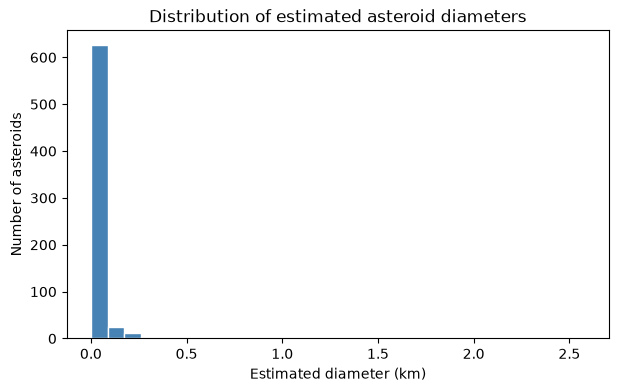

In [109]:
diameters = asteroids["diameter_km"]
positive_diameters = diameters.loc[(diameters > 0) & np.isfinite(diameters)].dropna()
print("Excluded from diameter histogram:", len(asteroids) - len(positive_diameters))

if positive_diameters.empty:
    print("No positive, finite diameter estimates to plot.")
else:
    fig, ax = plt.subplots()
    ax.hist(positive_diameters, bins=30, color="steelblue", edgecolor="white")
    ax.set(xlabel="Estimated diameter (km)", ylabel="Number of asteroids",
           title="Distribution of estimated asteroid diameters")
    plt.show()

**Your turn — probability distribution.** Plot a histogram of
`log10(impact_probability)` using only positive, finite probabilities at most 1.
Report the number excluded. For example, `log10(0.000001) = -6`.
Use a title and labels that make this transformation explicit.

Compare with a histogram on the original probability scale. Do zeros represent
reported zero estimates, rounding, or missing information? Check before interpreting.

In [110]:
# TODO: select valid probabilities with .between(0, 1, inclusive="right")
# and np.isfinite(...); use .dropna() for the plotting series.
# TODO: report the number of excluded rows.
# TODO: create original-scale and log10 histograms, with labels and plt.show().
# Hint: np.log10(positive_probabilities)

**Worked example — diameter versus cumulative probability.** Logarithmic axes
help display values spanning many orders of magnitude. They cannot display
zero or negative values. This mask excludes unsuitable values only from this plot.

Rows plotted: 683 | Excluded: 0


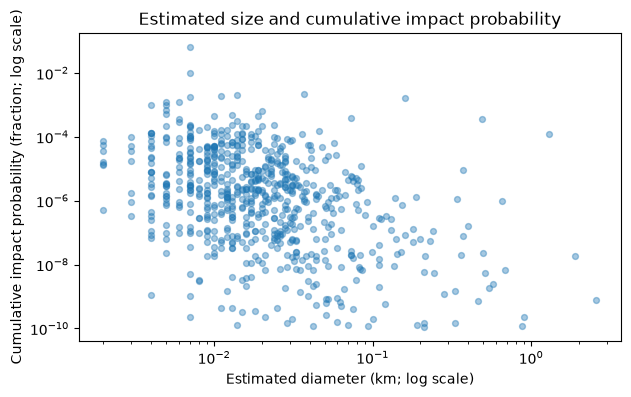

In [111]:
plot_mask = (
    (asteroids["diameter_km"] > 0)
    & np.isfinite(asteroids["diameter_km"])
    & asteroids["impact_probability"].between(0, 1, inclusive="right")
    & np.isfinite(asteroids["impact_probability"])
).fillna(False)
plot_data = asteroids.loc[plot_mask]
print("Rows plotted:", len(plot_data), "| Excluded:", len(asteroids) - len(plot_data))

if plot_data.empty:
    print("No valid positive pairs to plot.")
else:
    fig, ax = plt.subplots()
    ax.scatter(plot_data["diameter_km"], plot_data["impact_probability"], s=18, alpha=0.4)
    ax.set(xscale="log", yscale="log", xlabel="Estimated diameter (km; log scale)",
           ylabel="Cumulative impact probability (fraction; log scale)",
           title="Estimated size and cumulative impact probability")
    plt.show()

**Your turn — another relationship.** Plot absolute magnitude against estimated
diameter. Use a logarithmic diameter axis if helpful. Report the number of usable
pairs and label both axes.

**Prediction:** _TODO_

In [112]:
# TODO: select rows with finite absolute_magnitude and positive finite diameter_km.
# TODO: scatter absolute_magnitude against diameter_km; label axes and show the plot.

**Distribution:** Compare the mean and median with what the histograms show. _TODO_

**Relationship:** Describe direction, spread, and an unusual point in one scatterplot.
Identify the point by object name rather than assuming it is an error. _TODO_

**Interpretation:** Estimated diameter is often derived from magnitude and an
assumed reflectivity. How does that affect the independence of these variables?
Why does an association with cumulative probability not establish causation? _TODO_

## Exercise 3 — Compare groups and interpret risk scales

**Worked example — counts of an ordered category.** Examine Torino ratings first.
If all records have the same rating, a comparison between Torino groups cannot
answer a question about differences. Use the size groups below instead.

torino_max
0    680
Name: asteroid_count, dtype: Int64

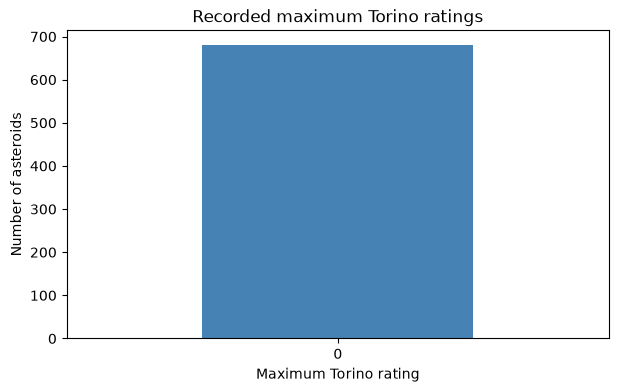

In [113]:
torino_counts = asteroids["torino_max"].value_counts().sort_index()
display(torino_counts.rename("asteroid_count"))
if not torino_counts.empty:
    fig, ax = plt.subplots()
    torino_counts.plot.bar(ax=ax, color="steelblue", rot=0)
    ax.set(xlabel="Maximum Torino rating", ylabel="Number of asteroids",
           title="Recorded maximum Torino ratings")
    plt.show()

**Worked example — define size groups.** These cutoffs are for this exercise;
they are not official hazard categories. Intervals include their upper boundary:
10 m belongs to the first group. Nonpositive or missing diameters remain ungrouped.
Keep counts alongside medians so that small groups are visible.

In [114]:
asteroids["size_group"] = pd.cut(
    asteroids["diameter_km"].where(asteroids["diameter_km"] > 0),
    bins=[0, 0.01, 0.1, 1, np.inf],
    labels=["Up to 10 m", "Over 10–100 m", "Over 100–1,000 m", "Over 1,000 m"],
)
group_summary = asteroids.groupby("size_group", observed=False).agg(
    asteroid_count=("object_name", "size"),
    probability_count=("impact_probability", "count"),
    median_probability=("impact_probability", "median"),
    median_palermo=("palermo_cumulative", "median"),
)
display(group_summary)
print("Ungrouped rows:", asteroids["size_group"].isna().sum())

,asteroid_count,probability_count,median_probability,median_palermo
size_group,,,,
Up to 10 m,202,202,0.000008,-6.965
Over 10–100 m,430,430,0.000001,-6.295
"Over 100–1,000 m",48,48,0.0,-5.205
"Over 1,000 m",3,3,0.0,-2.73


Ungrouped rows: 0


**Your turn — compare distributions.** Make a boxplot of cumulative Palermo
ratings by `size_group`. Show counts alongside your interpretation. A box shows
the middle 50% of values and its central line is the median; points beyond the
whiskers deserve investigation, not automatic deletion.

Palermo is already logarithmic: keep a linear axis for its signed ratings.
A negative rating is meaningful, not a missing-value code. See NASA's
[Palermo scale explanation](https://cneos.jpl.nasa.gov/sentry/palermo_scale.html).

In [115]:
# TODO: use asteroids.boxplot(column="palermo_cumulative", by="size_group", ...).
# Hint: fig, ax = plt.subplots(figsize=(9, 4)); pass ax=ax and grid=False.
# Remove the automatic supertitle with fig.suptitle("").
# TODO: label the plot and call plt.show().

**Compare:** Which groups differ in median and spread? Give evidence. _TODO_

**Check counts:** Which comparison needs the most caution because of its sample
size or missing values? _TODO_

**Critique:** Does a Torino rating of 0 mean a recorded probability is exactly
zero? Why is the most probable potential impact not necessarily the highest
Palermo-rated one? _TODO_

## Exercise 4 — Filter, derive a measure, and rank a subset

For an exploration exercise, select objects with **estimated diameter at least
0.1 km** and **cumulative probability at least 0.000001 (one in a million)**.
These are illustrative filters, not NASA alert criteria.

**Worked example — one condition.** `.loc` selects rows and columns; `.copy()`
keeps the subset separate. Combine conditions using `&` and parentheses.

In [116]:
large_mask = asteroids["diameter_km"] >= 0.1
large_objects = asteroids.loc[
    large_mask, ["object_name", "diameter_km", "impact_probability"]
].copy()
print("Objects at least 0.1 km across:", len(large_objects))
display(large_objects.head())

Objects at least 0.1 km across: 53


,object_name,diameter_km,impact_probability
4,2015 ME131,0.497,0.0
5,2010 XB73,0.11,0.0
10,2015 HV182,0.153,0.000001
27,2014 MV67,0.541,0.0
28,2016 JT38,0.212,0.0


**Your turn — combine conditions.** Create `matching_asteroids` with both
conditions, preserving every column and the original row index. Report the
subset size and summarize diameter and cumulative probability. An empty subset
is a valid result; explain it rather than changing the criteria silently.

In [117]:
min_diameter_km = 0.1
min_probability = 1e-6

matching_asteroids = None  # TODO: replace with asteroids.loc[mask].copy().
# TODO: report its size and summarize diameter_km and impact_probability.

In [118]:
# Checkpoint: verifies your selection, including completeness.
if matching_asteroids is None:
    print("INCOMPLETE: create matching_asteroids in the previous cell.")
else:
    expected_mask = (
        (asteroids["diameter_km"] >= min_diameter_km)
        & (asteroids["impact_probability"] >= min_probability)
    ).fillna(False)
    assert matching_asteroids.index.equals(asteroids.index[expected_mask]), (
        "Select all matching rows and preserve their original order and index."
    )
    assert set(asteroids.columns).issubset(matching_asteroids.columns), "Keep all columns."
    print("Filter checkpoint passed. Matching rows:", len(matching_asteroids))

INCOMPLETE: create matching_asteroids in the previous cell.


**Your turn — derive and rank.**

1. Add `diameter_m = diameter_km * 1000` to your subset.
2. Add `period_span_years = period_end - period_start`. This is the distance
   between the endpoints, not an annual impact rate. A same-year range has span 0.
3. Create `shortlist` with the five highest cumulative probabilities among matching
   objects, or every matching object if fewer than five qualify.
4. Display names, year endpoints, diameter in meters, probability, span, and
   cumulative Palermo rating. Retain all columns in `shortlist` itself.

Do not divide the probability by the year span: individual scenario dates and
probabilities are not available in this summary table.

In [119]:
shortlist = None  # TODO: replace after completing the subset.

# TODO: add diameter_m and period_span_years to matching_asteroids.
# TODO: rank using .sort_values("impact_probability", ascending=False).head(5).
# TODO: display a readable selection of the requested columns.

In [120]:
# Checkpoint: checks membership, derived units, and the ranking cutoff.
if matching_asteroids is None or shortlist is None:
    print("INCOMPLETE: finish the subset, derived columns, and shortlist.")
else:
    assert {"diameter_m", "period_span_years"}.issubset(shortlist.columns), "Add both measures."
    assert set(matching_asteroids.columns).issubset(shortlist.columns), "Keep all columns."
    assert shortlist.index.is_unique and shortlist.index.isin(matching_asteroids.index).all()
    assert len(shortlist) == min(5, len(matching_asteroids)), "Check shortlist length."
    assert shortlist["impact_probability"].is_monotonic_decreasing, "Sort highest first."
    assert np.allclose(shortlist["diameter_m"].to_numpy(dtype=float),
                       shortlist["diameter_km"].to_numpy(dtype=float) * 1000)
    assert np.allclose(shortlist["period_span_years"].to_numpy(dtype=float),
                       (shortlist["period_end"] - shortlist["period_start"]).to_numpy(dtype=float),
                       equal_nan=True)
    if len(shortlist):
        cutoff = matching_asteroids["impact_probability"].nlargest(len(shortlist)).min()
        assert (shortlist["impact_probability"] >= cutoff).all(), "Check the selected top values."
    print("Shortlist checkpoint passed.")

INCOMPLETE: finish the subset, derived columns, and shortlist.


**Compare:** How does the subset's median diameter and cumulative probability
compare with the full table? _TODO_

**Describe one object:** Give its name, estimated size, probability, and year
range. Describe why it appears in the shortlist without presenting it as a
confirmed collision or a current hazard assessment. _TODO_

**Change the ranking:** Would ranking by cumulative Palermo rating give the
same five objects? Compare the lists and explain why they can differ. _TODO_

In [121]:
# TODO: create a second shortlist ranked by palermo_cumulative, descending.
# TODO: compare object names with the probability-based shortlist.

## Final reflection

**Two findings:** Give two findings, each supported by a numerical result or a
specific plot. _TODO_

**One limitation:** Explain how the snapshot date, model uncertainty, selected
Sentry population, or estimated sizes restrict what you can conclude. _TODO_

**One next question:** Propose a small extension and name any extra data needed. _TODO_

### Optional extensions

- Calculate a Spearman correlation table for selected numerical variables.
  Explain why correlation between estimated size and magnitude is partly built in.
- Highlight the shortlist in the diameter–probability scatterplot.
- Compare size-group medians with another set of group boundaries.
- Compare this snapshot with a separately dated Sentry export, matching by object
  designation. Document changed definitions and renamed or removed objects.

### Completion checklist

- Complete core TODOs and written answers; do not leave `None` placeholders.
- Document parsing problems, missing values, exclusions, and cleaning decisions.
- Give figures titles, readable labels, and units; explain log scales.
- Run both Exercise 4 checkpoints, restart the kernel, and run all cells.
- Save your completed notebook with its outputs and dataset provenance.